In [1]:
import os

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from idxlab.clean import clean_ticker_data
from idxlab.config import load_config
from idxlab.data import DataLoader
from idxlab.evaluation import (
    bootstrap_auc_ci,
    evaluate_classifier,
    paired_bootstrap_auc_diff,
)
from idxlab.logging_setup import setup_logging
from idxlab.split import build_dataset, time_based_split
from idxlab.backtest import proba_to_signal, run_backtest
from idxlab.metrics import exposure_matched_return, summarize

Path("docs/results").mkdir(parents=True, exist_ok=True)
Path("docs/figures").mkdir(parents=True, exist_ok=True)

cfg = load_config()
setup_logging(cfg.log_level)
loader = DataLoader.from_config(cfg)
raw = loader.load_all()

13:32:20 | INFO     | idxlab.data | Cache hit for BBCA.JK (data\raw\BBCA_JK.parquet)
13:32:20 | INFO     | idxlab.data | Cache hit for BBRI.JK (data\raw\BBRI_JK.parquet)
13:32:20 | INFO     | idxlab.data | Cache hit for TLKM.JK (data\raw\TLKM_JK.parquet)
13:32:20 | INFO     | idxlab.data | Cache hit for ASII.JK (data\raw\ASII_JK.parquet)
13:32:20 | INFO     | idxlab.data | Cache hit for UNVR.JK (data\raw\UNVR_JK.parquet)


In [3]:
best = json.loads(Path("docs/results/day16_best_params.json").read_text(encoding="utf-8"))

# Order matters: simplest first. This is the challenge order in the protocol.
candidates = {
    "logreg": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "rf_default": RandomForestClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=42, n_jobs=-1
    ),
    "rf_tuned": RandomForestClassifier(**best["rf"]),
    "xgb_default": XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", random_state=42, n_jobs=1,
    ),
    "xgb_tuned": XGBClassifier(**best["xgb"]),
}
dummy = DummyClassifier(strategy="most_frequent")  # reference only, not a candidate

chosen = "logreg"                  # sama dengan Day 20 (hasil Day 18)
model = candidates[chosen]

In [5]:
def backtest_one(ohlcv: pd.DataFrame, model, threshold: float = 0.5):
    """Fit on train only, backtest on validation. Returns (daily, returns)."""
    dataset = build_dataset(ohlcv)                        
    split = time_based_split(dataset)
    feature_cols = [c for c in dataset.columns if c not in ("forward_return", "direction")]

    fitted = clone(model)                                 
    fitted.fit(split.train[feature_cols], split.train["direction"].astype(int))  

    proba = pd.Series(
        fitted.predict_proba(split.val[feature_cols])[:, 1],
        index=split.val.index,
    )
    returns = ohlcv["Close"].pct_change().loc[split.val.index]  

    daily = run_backtest(returns, proba_to_signal(proba, threshold))
    return daily, returns

In [6]:
rows, runs = {}, {}
for ticker in cfg.tickers:
    ohlcv = clean_ticker_data(raw[ticker])                            
    daily, returns = backtest_one(ohlcv, model)

    s = summarize(daily)
    s["bench_matched"] = exposure_matched_return(returns, s["exposure"])
    s["n_val_days"] = float(len(daily))
    rows[ticker], runs[ticker] = s, daily
    print(ticker, daily.index.min().date(), "->", daily.index.max().date())

table = pd.DataFrame(rows).T
table.round(3)

BBCA.JK 2025-08-11 -> 2026-02-12
BBRI.JK 2025-08-11 -> 2026-02-12
TLKM.JK 2025-08-11 -> 2026-02-12
ASII.JK 2025-08-11 -> 2026-02-12
UNVR.JK 2025-08-11 -> 2026-02-12


,cum_return,sharpe,max_drawdown,win_rate,n_trades,exposure,total_cost,bench_cum_return,bench_sharpe,bench_max_drawdown,bench_matched,n_val_days
BBCA.JK,-0.038,-0.563,-0.096,0.250,4.0,0.189,0.016,-0.112,-0.644,-0.208,-0.019,127.0
BBRI.JK,-0.003,-0.012,-0.079,0.429,7.0,0.118,0.028,0.063,0.552,-0.176,0.009,127.0
TLKM.JK,0.253,1.508,-0.117,1.000,6.0,0.764,0.022,0.211,1.085,-0.165,0.167,127.0
ASII.JK,0.000,NaN,0.000,NaN,0.0,0.000,0.000,0.401,1.874,-0.166,0.000,127.0
UNVR.JK,0.000,NaN,0.000,NaN,0.0,0.000,0.000,0.359,1.443,-0.329,0.000,127.0


In [7]:
ROOT = Path.cwd() if (Path.cwd() / "docs").exists() else Path.cwd().parent
(ROOT / "docs" / "results").mkdir(parents=True, exist_ok=True)
table.round(4).to_csv(ROOT / "docs" / "results" / "day21_ticker_comparison.csv")

wins_vs_bh = int((table["cum_return"] > table["bench_cum_return"]).sum())
wins_vs_matched = int((table["cum_return"] > table["bench_matched"]).sum())
print(f"Return lebih tinggi dari buy & hold         : {wins_vs_bh} dari {len(table)} ticker")
print(f"Return lebih tinggi dari exposure-matched   : {wins_vs_matched} dari {len(table)} ticker")

Return lebih tinggi dari buy & hold         : 2 dari 5 ticker
Return lebih tinggi dari exposure-matched   : 1 dari 5 ticker


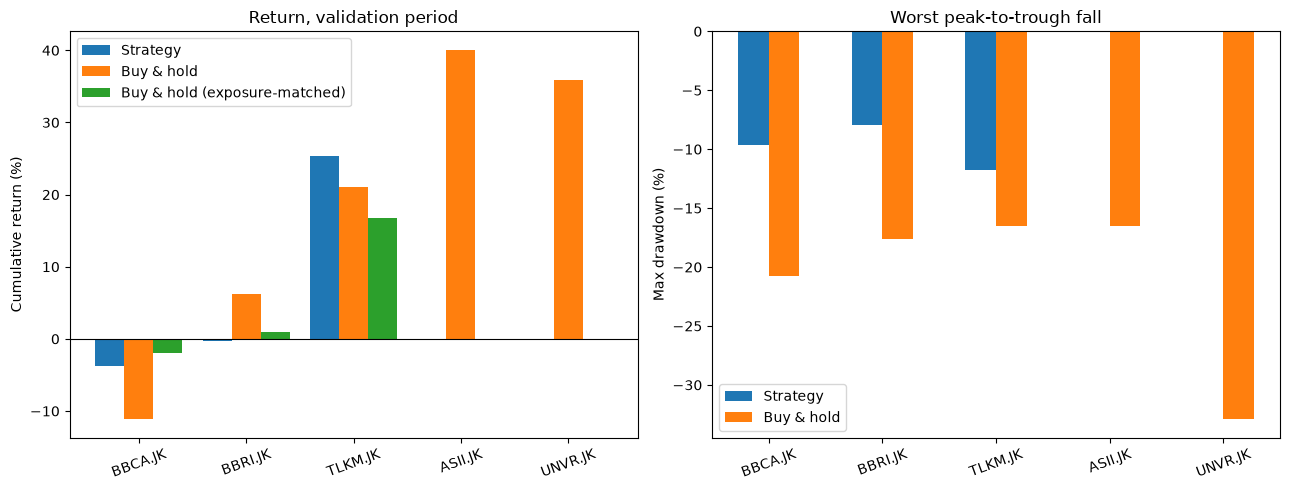

In [8]:
x = np.arange(len(table))
w = 0.27
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.bar(x - w, table["cum_return"] * 100, w, label="Strategy")
ax1.bar(x, table["bench_cum_return"] * 100, w, label="Buy & hold")
ax1.bar(x + w, table["bench_matched"] * 100, w, label="Buy & hold (exposure-matched)")
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_xticks(x)
ax1.set_xticklabels(table.index, rotation=20)
ax1.set_ylabel("Cumulative return (%)")
ax1.set_title("Return, validation period")
ax1.legend()

ax2.bar(x - w / 2, table["max_drawdown"] * 100, w, label="Strategy")
ax2.bar(x + w / 2, table["bench_max_drawdown"] * 100, w, label="Buy & hold")
ax2.set_xticks(x)
ax2.set_xticklabels(table.index, rotation=20)
ax2.set_ylabel("Max drawdown (%)")
ax2.set_title("Worst peak-to-trough fall")
ax2.legend()

plt.tight_layout()
(ROOT / "docs" / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(ROOT / "docs" / "figures" / "day21_ticker_comparison.png", dpi=150)
plt.show()

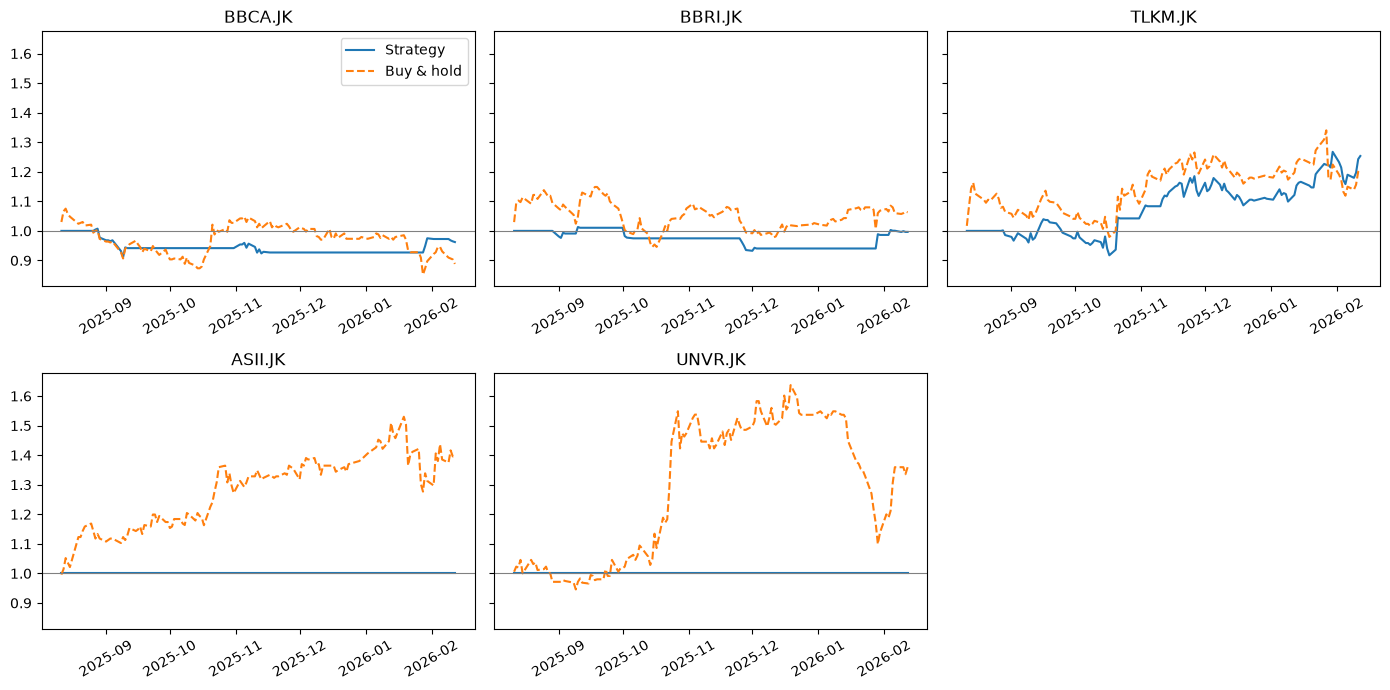

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, (ticker, d) in zip(axes.flat, runs.items()):
    ax.plot(d.index, d["equity"], label="Strategy")
    ax.plot(d.index, d["benchmark_equity"], linestyle="--", label="Buy & hold")
    ax.axhline(1.0, color="grey", linewidth=0.8)
    ax.set_title(ticker)
    ax.tick_params(axis="x", rotation=30)
for ax in axes.flat[len(runs):]:
    ax.set_visible(False)
axes.flat[0].legend()
plt.tight_layout()
plt.savefig(ROOT / "docs" / "figures" / "day21_equity_curves.png", dpi=150)
plt.show()